In [ ]:
# --- Imports de base ---
import os, glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array

In [ ]:
# --- Colab: monter Google Drive ---
from google.colab import drive
drive.mount('/content/drive')

# --- Chemins (adapte si besoin) ---
BASE = "/content/drive/MyDrive/SI"

DIR_IMAGES = os.path.join(BASE, "data_2023")            # Images RGB
DIR_MASK_EXPERT = os.path.join(BASE, "mask_via_2023")   # Masques expertise humaine
DIR_MASK_OPENCV = os.path.join(BASE, "mask_opencv_2023")# Masques OpenCV

DIR_OUT_FIGS = os.path.join(BASE, "visualisations_couleurs", "comparaisons_masks")
DIR_OUT_CSV  = os.path.join(BASE, "metriques")
os.makedirs(DIR_OUT_FIGS, exist_ok=True)
os.makedirs(DIR_OUT_CSV,  exist_ok=True)

MODEL_PATH = os.path.join(BASE, "model_only_2023.keras")  # fichier existant chez toi
print("Model path:", MODEL_PATH)

Mounted at /content/drive
Model path: /content/drive/MyDrive/SI/model_only_2023.keras


In [ ]:
# Charger le modèle UNet
from tensorflow.keras.utils import register_keras_serializable
import tensorflow.keras.backend as K
@register_keras_serializable()
def dice_coef(y_true, y_pred, smooth=1):
    intersection = K.sum(y_true * y_pred, axis=[1,2,3])
    union = K.sum(y_true, axis=[1,2,3]) + K.sum(y_pred, axis=[1,2,3])
    return K.mean((2. * intersection + smooth) / (union + smooth), axis=0)

@register_keras_serializable()
def dice_loss(y_true, y_pred):
    return 1 - dice_coef(y_true, y_pred)

@register_keras_serializable()
def combined_loss(y_true, y_pred):
    return binary_crossentropy(y_true, y_pred) + dice_loss(y_true, y_pred)

model = load_model("/content/drive/MyDrive/SI/callbacks/model_2023_only.keras")

# Récupérer la taille d'entrée attendue (H, W, C)
input_shape = model.input_shape  # ex: (None, 256, 256, 3)
H, W, C = input_shape[1], input_shape[2], input_shape[3]
print("Model input shape:", (H, W, C))

Model input shape: (160, 160, 3)


In [ ]:
def read_rgb_resize(path, size=(256,256)):
    """Lit une image RGB et la redimensionne à size. Retour: tableau float32 [0,1]."""
    img = load_img(path, target_size=size)   # PIL → RGB
    arr = img_to_array(img) / 255.0          # [H,W,3] en [0,1]
    return arr

def read_mask_binary(path, size=(256,256)):
    """Lit un masque (png/jpg), convertit en binaire {0,1}, redimensionné à size."""
    # On lit en niveaux de gris
    m = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if m is None:
        return None
    m = cv2.resize(m, size, interpolation=cv2.INTER_NEAREST)
    # binarisation (127 seuil)
    m = (m > 127).astype(np.uint8)
    return m

def predict_unet_mask(img_rgb):
    """Prédit le masque binaire {0,1} via le modèle, à partir d'une image RGB [0,1]."""
    x = np.expand_dims(img_rgb, axis=0)  # [1,H,W,3]
    pred = model.predict(x, verbose=0)[0]  # [H,W,1] ou [H,W] selon le modèle
    if pred.ndim == 3:
        pred = pred[..., 0]
    # seuillage à 0.5
    m = (pred >= 0.5).astype(np.uint8)
    return m

def iou(mask_a, mask_b):
    """Intersection over Union pour masques binaires {0,1}."""
    inter = np.logical_and(mask_a==1, mask_b==1).sum()
    union = np.logical_or(mask_a==1, mask_b==1).sum()
    return inter / union if union > 0 else 1.0  # si tout vide, on met 1.0 par convention

def dice(mask_a, mask_b):
    """Dice coefficient pour masques binaires {0,1}."""
    inter = np.logical_and(mask_a==1, mask_b==1).sum()
    s = (mask_a==1).sum() + (mask_b==1).sum()
    return (2*inter) / s if s > 0 else 1.0


import csv
csv_path = os.path.join(DIR_OUT_CSV, "metrics_opencv_unet_vs_expert_2023.csv")
i = 0
with open(csv_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow([
        "filename",
        "IoU_OpenCV_vs_Expert", "Dice_OpenCV_vs_Expert", "Acc_OpenCV_vs_Expert", "Cosine_OpenCV_vs_Expert",
        "IoU_UNet_vs_Expert",  "Dice_UNet_vs_Expert",  "Acc_UNet_vs_Expert", "Cosine_UNet_vs_Expert"
    ])

    for ipath in img_paths:
        base = os.path.splitext(os.path.basename(ipath))[0]
        i += 1
        # Chercher masques expert & opencv
        cand_exts = [".png", ".jpg", ".jpeg"]
        m_expert_path = None
        m_opencv_path = None
        for ext in cand_exts:
            p1 = os.path.join(DIR_MASK_EXPERT, "mask_" + base + ext)
            p2 = os.path.join(DIR_MASK_OPENCV, "mask_" + base + ext)
            if m_expert_path is None and os.path.exists(p1):
                m_expert_path = p1
            if m_opencv_path is None and os.path.exists(p2):
                m_opencv_path = p2

        if (m_expert_path is None) or (m_opencv_path is None):
            print(f"[WARN] Masque manquant pour {base} -> expert:{m_expert_path} opencv:{m_opencv_path}")
            continue

        # Charger image + masques aux tailles du modèle
        img_rgb = read_rgb_resize(ipath, size=(W, H))
        m_expert = read_mask_binary(m_expert_path, size=(W, H))
        m_opencv = read_mask_binary(m_opencv_path, size=(W, H))

        if (m_expert is None) or (m_opencv is None):
            print(f"[WARN] Lecture masque échouée pour {base}")
            continue

        # Prédire avec UNet
        m_unet = predict_unet_mask(img_rgb)

        # Mesures OpenCV vs Expert
        iou_oe = iou(m_opencv, m_expert)
        dice_oe = dice(m_opencv, m_expert)
        acc_oe  = accuracy_score_custom(m_opencv, m_expert)
        cos_oe  = cosine_similarity_custom(m_opencv, m_expert)

        # Mesures UNet vs Expert
        iou_ue = iou(m_unet, m_expert)
        dice_ue = dice(m_unet, m_expert)
        acc_ue  = accuracy_score_custom(m_unet, m_expert)
        cos_ue  = cosine_similarity_custom(m_unet, m_expert)

        # Ligne CSV
        writer.writerow([base, iou_oe, dice_oe, acc_oe, cos_oe, iou_ue, dice_ue, acc_ue, cos_ue])

print("✅ Terminé. CSV:", csv_path)

In [ ]:
def read_mask_binary(path, size=(256,256)):
    """Lit un masque (png/jpg), convertit en binaire {0,1}, redimensionné à size."""
    # On lit en niveaux de gris
    m = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if m is None:
        return None
    m = cv2.resize(m, size, interpolation=cv2.INTER_NEAREST)
    # binarisation (127 seuil)
    m = (m > 127).astype(np.uint8)
    return m

In [ ]:
def predict_unet_mask(img_rgb):
    """Prédit le masque binaire {0,1} via le modèle, à partir d'une image RGB [0,1]."""
    x = np.expand_dims(img_rgb, axis=0)  # [1,H,W,3]
    pred = model.predict(x, verbose=0)[0]  # [H,W,1] ou [H,W] selon le modèle
    if pred.ndim == 3:
        pred = pred[..., 0]
    # seuillage à 0.5
    m = (pred >= 0.5).astype(np.uint8)
    return m

In [ ]:
def iou(mask_a, mask_b):
    """Intersection over Union pour masques binaires {0,1}."""
    inter = np.logical_and(mask_a==1, mask_b==1).sum()
    union = np.logical_or(mask_a==1, mask_b==1).sum()
    return inter / union if union > 0 else 1.0  # si tout vide, on met 1.0 par convention

In [ ]:
def dice(mask_a, mask_b):
    """Dice coefficient pour masques binaires {0,1}."""
    inter = np.logical_and(mask_a==1, mask_b==1).sum()
    s = (mask_a==1).sum() + (mask_b==1).sum()
    return (2*inter) / s if s > 0 else 1.0

In [ ]:
def cosine_similarity_custom(mask1, mask2):
    """Cosine similarity between two masks."""
    v1 = mask1.astype(float).flatten()
    v2 = mask2.astype(float).flatten()
    dot_product = np.dot(v1, v2)
    norm_product = np.linalg.norm(v1) * np.linalg.norm(v2)
    return dot_product / norm_product if norm_product > 0 else 0.0

In [ ]:
def cosine_similarity_custom(mask1, mask2):
    """Cosine similarity between two masks."""
    v1 = mask1.astype(float).flatten()
    v2 = mask2.astype(float).flatten()
    dot_product = np.dot(v1, v2)
    norm_product = np.linalg.norm(v1) * np.linalg.norm(v2)
    return dot_product / norm_product if norm_product > 0 else 0.0

In [ ]:
def accuracy_score_custom(mask_pred, mask_true):
    """Pixel accuracy for binary masks."""
    mask_pred = mask_pred.astype(bool)
    mask_true = mask_true.astype(bool)
    correct = (mask_pred == mask_true).sum()
    total = mask_true.size
    return correct / total

In [ ]:
def save_triptych(expert, opencv, unet, out_path, titles=("Expert", "OpenCV", "UNet")):
    """Sauvegarde une image 3 colonnes avec les masques binaires en niveaux de gris."""
    plt.figure(figsize=(9,3))
    for i, (m, t) in enumerate(zip([expert, opencv, unet], titles), start=1):
        plt.subplot(1,3,i)
        plt.imshow(m, cmap='gray', vmin=0, vmax=1)
        plt.title(t)
        plt.axis('off')
    plt.tight_layout()
    plt.savefig(out_path, dpi=150, bbox_inches='tight')
    plt.close()

In [ ]:
# Lister les images RGB (png/jpg/jpeg)
img_paths = sorted(
    glob.glob(os.path.join(DIR_IMAGES, "*.png")) +
    glob.glob(os.path.join(DIR_IMAGES, "*.jpg")) +
    glob.glob(os.path.join(DIR_IMAGES, "*.jpeg"))
)

len(img_paths), img_paths[:3]

(2552,
 ['/content/drive/MyDrive/SI/data_2023/prod_2023-01-01T03-00-00.000Z.png',
  '/content/drive/MyDrive/SI/data_2023/prod_2023-01-01T06-00-00.000Z.png',
  '/content/drive/MyDrive/SI/data_2023/prod_2023-01-01T09-00-00.000Z.png'])

In [ ]:
import csv
csv_path = os.path.join(DIR_OUT_CSV, "metrics_opencv_unet_vs_expert_2023.csv")
i = 0
with open(csv_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow([
        "filename",
        "IoU_OpenCV_vs_Expert", "Dice_OpenCV_vs_Expert", "Acc_OpenCV_vs_Expert", "Cosine_OpenCV_vs_Expert",
        "IoU_UNet_vs_Expert",  "Dice_UNet_vs_Expert",  "Acc_UNet_vs_Expert", "Cosine_UNet_vs_Expert"
    ])

    for ipath in img_paths:
        base = os.path.splitext(os.path.basename(ipath))[0]
        i += 1
        # Chercher masques expert & opencv
        cand_exts = [".png", ".jpg", ".jpeg"]
        m_expert_path = None
        m_opencv_path = None
        for ext in cand_exts:
            p1 = os.path.join(DIR_MASK_EXPERT, "mask_" + base + ext)
            p2 = os.path.join(DIR_MASK_OPENCV, "mask_" + base + ext)
            if m_expert_path is None and os.path.exists(p1):
                m_expert_path = p1
            if m_opencv_path is None and os.path.exists(p2):
                m_opencv_path = p2

        if (m_expert_path is None) or (m_opencv_path is None):
            print(f"[WARN] Masque manquant pour {base} -> expert:{m_expert_path} opencv:{m_opencv_path}")
            continue

        # Charger image + masques aux tailles du modèle
        img_rgb = read_rgb_resize(ipath, size=(W, H))
        m_expert = read_mask_binary(m_expert_path, size=(W, H))
        m_opencv = read_mask_binary(m_opencv_path, size=(W, H))

        if (m_expert is None) or (m_opencv is None):
            print(f"[WARN] Lecture masque échouée pour {base}")
            continue

        # Prédire avec UNet
        m_unet = predict_unet_mask(img_rgb)

        # Mesures OpenCV vs Expert
        iou_oe = iou(m_opencv, m_expert)
        dice_oe = dice(m_opencv, m_expert)
        acc_oe  = accuracy_score_custom(m_opencv, m_expert)
        cos_oe  = cosine_similarity_custom(m_opencv, m_expert)

        # Mesures UNet vs Expert
        iou_ue = iou(m_unet, m_expert)
        dice_ue = dice(m_unet, m_expert)
        acc_ue  = accuracy_score_custom(m_unet, m_expert)
        cos_ue  = cosine_similarity_custom(m_unet, m_expert)

        # Ligne CSV
        writer.writerow([base, iou_oe, dice_oe, acc_oe, cos_oe, iou_ue, dice_ue, acc_ue, cos_ue])

print("✅ Terminé. CSV:", csv_path)
print("✅ Images comparatives dans:", DIR_OUT_FIGS)

1/2552
2/2552
3/2552
4/2552
5/2552
6/2552
7/2552
8/2552
9/2552
10/2552
11/2552
12/2552
13/2552
14/2552
15/2552
16/2552
17/2552
18/2552
19/2552
20/2552
21/2552
22/2552
23/2552
24/2552
25/2552
26/2552
27/2552
28/2552
29/2552
30/2552
31/2552
32/2552
33/2552
34/2552
35/2552
36/2552
37/2552
38/2552
39/2552
40/2552
41/2552
42/2552
43/2552
44/2552
45/2552
46/2552
47/2552
48/2552
49/2552
50/2552
51/2552
52/2552
53/2552
54/2552
55/2552
56/2552
57/2552
58/2552
59/2552
60/2552
61/2552
62/2552
63/2552
64/2552
65/2552
66/2552
67/2552
68/2552
69/2552
70/2552
71/2552
72/2552
73/2552
74/2552
75/2552
76/2552
77/2552
78/2552
79/2552
80/2552
81/2552
82/2552
83/2552
84/2552
85/2552
86/2552
87/2552
88/2552
89/2552
90/2552
91/2552
92/2552
93/2552
94/2552
95/2552
96/2552
97/2552
98/2552
99/2552
100/2552
101/2552
102/2552
103/2552
104/2552
105/2552
106/2552
107/2552
108/2552
109/2552
110/2552
111/2552
112/2552
113/2552
114/2552
115/2552
116/2552
117/2552
118/2552
119/2552
120/2552
121/2552
122/2552
123/2552
1

In [ ]:
def save_mask_binary(mask, path):
    """Save binary mask (0/1) as PNG (0/255 grayscale)."""
    mask_img = (mask.astype(np.uint8) * 255)
    Image.fromarray(mask_img, mode="L").save(path)

In [ ]:
DIR_OUT_MASKS = "/content/drive/MyDrive/SI/mask_2023_unet"
from tqdm import tqdm   # <-- Import tqdm
os.makedirs(DIR_OUT_MASKS,exist_ok=True)
for ipath in tqdm(img_paths, desc="Generating UNet masks", unit="image"):
    base = os.path.splitext(os.path.basename(ipath))[0]  # ex: prod_2023-...

    # Load and resize
    img_rgb = read_rgb_resize(ipath, size=(W, H))

    # Predict mask using UNet
    m_unet = predict_unet_mask(img_rgb)   # Must return 2D array with 0/1

    # Save to folder
    out_path = os.path.join(DIR_OUT_MASKS, f"mask_{base}.png")
    save_mask_binary(m_unet, out_path)

Generating UNet masks:   0%|          | 0/2552 [00:00<?, ?image/s]/tmp/ipython-input-1954935172.py:4: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(mask_img, mode="L").save(path)
Generating UNet masks: 100%|██████████| 2552/2552 [05:01<00:00,  8.45image/s]


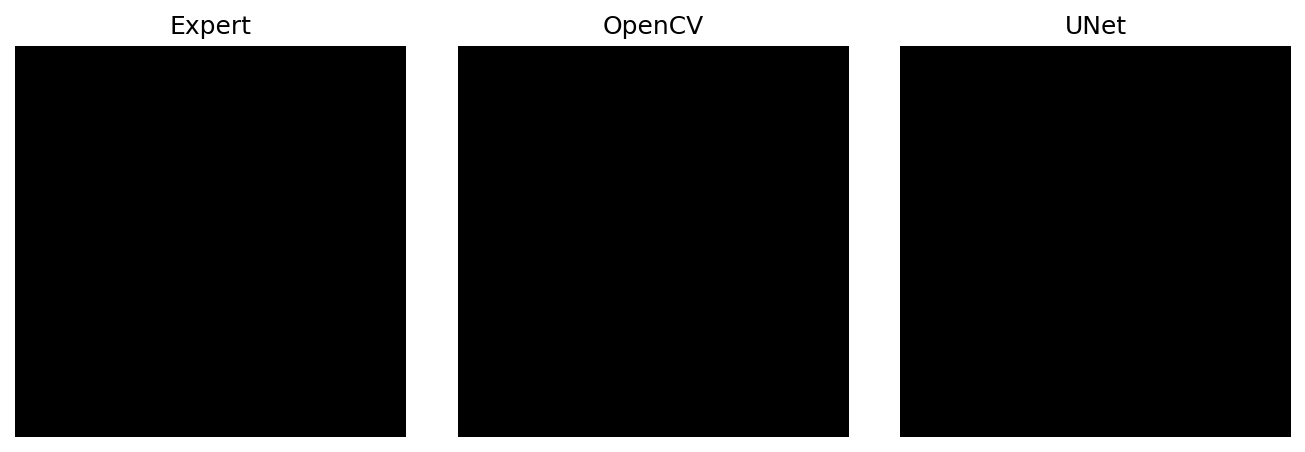

In [ ]:
from IPython.display import Image, display
# Afficher l'un des triptyques générés
samples = sorted(glob.glob(os.path.join(DIR_OUT_FIGS, "*_expert_opencv_unet.png")))
if samples:
    display(Image(filename=samples[0]))
else:
    print("Aucun triptyque trouvé (vérifie les dossiers/nommages).")